<div dir="rtl" style="text-align: right;">

# چالش آماری علم داده ترم 3 (شماره 4)

- نام: Kiarash Akbari
- مجموعه: آزمایشگاه فناوری های مالی داتین
- تاریخ: 8 آبان 1405
- فایل داده: bank_season3_part2.csv با 600 مشتری بانک
- پاسخ ها: n_overdraft برای سوال 1 و avg_overdraft_mrial برای سوال 2

### 1. تنظیمات اولیه

کتابخانه ها و مسیر داده را می گذارم و seed را 42 می گذارم. توی این کوییز train و test نداریم. سوال 1 روی هر 600 مشتری است و سوال 2 روی مشتری هایی که حداقل یک اضافه برداشت دارند. خروجی ها و نمودارها داخل همین فایل ذخیره می شوند.

</div>

In [ ]:
import io
import warnings
from pathlib import Path
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats, special
from scipy.optimize import minimize_scalar
from statsmodels.stats.diagnostic import het_breuschpagan
from IPython.display import display, Image
warnings.filterwarnings('ignore')

SEED = 42
np.random.seed(SEED)
pd.set_option('display.width', 170)
pd.set_option('display.max_columns', 30)
plt.rcParams['figure.dpi'] = 110

def show():
    b = io.BytesIO()
    plt.gcf().savefig(b, format='png', bbox_inches='tight')
    plt.close()
    display(Image(b.getvalue()))

def find_data():
    p = Path.cwd().resolve()
    for f in [p, *p.parents]:
        for q in [f / 'bank_season3_part2.csv', f / 'dataset' / 'bank_season3_part2.csv',
                  f / 'datasets' / 'bank_season3_part2.csv', f / 'term-3' / 'datasets' / 'bank_season3_part2.csv']:
            if q.exists():
                return q
    raise FileNotFoundError('bank_season3_part2.csv not found')

raw = pd.read_csv(find_data())
print('shape:', raw.shape)
print('duplicate rows:', raw.duplicated().sum(), '| unique id:', raw['customer_id'].is_unique)
print('missing:', raw.isna().sum().loc[lambda s: s > 0].to_dict())
print('missing avg_overdraft iff no event:', ((raw['n_overdraft'] == 0) == raw['avg_overdraft_mrial'].isna()).all())
print('minimum of columns that get a log:', raw[['total_inflow_mrial', 'credit_limit_mrial', 'card_spend_total_mrial', 'exposure_months']].min().to_dict())
print('customers with n_overdraft > 0:', int((raw['n_overdraft'] > 0).sum()))
assert raw.shape == (600, 35) and raw['customer_id'].is_unique
assert (raw[['total_inflow_mrial', 'credit_limit_mrial', 'card_spend_total_mrial', 'exposure_months']] > 0).all().all()

shape: (600, 35)
duplicate rows: 0 | unique id: True
missing: {'avg_overdraft_mrial': 212}
missing avg_overdraft iff no event: True
minimum of columns that get a log: {'total_inflow_mrial': 36.5, 'credit_limit_mrial': 24.2, 'card_spend_total_mrial': 14.0, 'exposure_months': 6.0}
customers with n_overdraft > 0: 388


<div dir="rtl" style="text-align: right;">

600 سطر و 35 ستون داریم و شناسه تکراری نداریم. فقط avg_overdraft_mrial گمشده دارد، 212 سطر، که دقیقا همان مشتری هایی هستند که n_overdraft صفر دارند. این گمشدگی ساختاری است، چون میانگین مبلغ برای کسی که اضافه برداشت نکرده تعریف نمی شود، و چیزی را پر نمی کنم. سوال 2 همین مشتری ها را کنار می گذارد و 388 نفر می ماند. کل واریزی و سقف اعتبار و هزینه کارتی و مدت مشاهده همه مثبت اند، پس لگاریتم شان مشکلی ندارد.

### 2. سوال 1: داده و مدل مبنا

y برابر n_overdraft و t برابر exposure_months است. پیش بین ها credit_utilization و atm_withdrawals و branch_visits و savings_ratio و age و لگاریتم total_inflow_mrial هستند، با عرض از مبدا. پس هفت پارامتر داریم و درجه آزادی باقی مانده 593 می شود. جمله لگاریتم مدت مشاهده offset است، یعنی ضریبش ثابت و برابر 1 است.

</div>

In [ ]:
d = raw.copy()
d['ln_inflow'] = np.log(d['total_inflow_mrial'])
d['ln_t'] = np.log(d['exposure_months'])
pred1 = ['credit_utilization', 'atm_withdrawals', 'branch_visits', 'savings_ratio', 'age', 'ln_inflow']
X1 = sm.add_constant(d[pred1])
y1 = d['n_overdraft'].astype(float)
t1 = d['exposure_months'].astype(float)
off1 = np.log(t1)
n1, p1 = X1.shape
print('n =', n1, '| p =', p1, '| residual df =', n1 - p1)
print('y: mean %.3f, variance %.3f, zeros %d (%.1f%%), max %d' % (y1.mean(), y1.var(), (y1 == 0).sum(), 100 * (y1 == 0).mean(), y1.max()))
print('exposure_months: min %d, max %d, mean %.2f' % (t1.min(), t1.max(), t1.mean()))
print('corr(y, exposure) = %.3f' % y1.corr(t1))

n = 600 | p = 7 | residual df = 593
y: mean 2.342, variance 12.623, zeros 212 (35.3%), max 30
exposure_months: min 6, max 36, mean 20.59
corr(y, exposure) = 0.286


<div dir="rtl" style="text-align: right;">

میانگین y برابر 2.342 و واریانسش 12.623 است و 212 مشتری (35.3 درصد) هیچ اضافه برداشتی ندارند. این واریانس بزرگ مربوط به خود y است، نه به باقی مانده های مدل، پس به تنهایی ثابت نمی کند پراکندگی بیشتر از پواسون است. این را بعد از برازش با phi_hat چک می کنم. همبستگی y با مدت مشاهده 0.286 است، یعنی مدت مشاهده برای مدل مهم است.

### 3. سوال 1-الف: پواسون با پیوند لگاریتمی و offset

مدل را برازش می دهم و جدول ضرایب را با خطای معیار، z، نسبت نرخ و فاصله اطمینان 95 درصد می نویسم. انحراف مدل و انحراف مدل تهی (فقط عرض از مبدا و offset) و آماره پیرسون و phi_hat را هم دستی حساب می کنم و با کتابخانه مقایسه می کنم.

</div>

In [ ]:
pois = sm.GLM(y1, X1, family=sm.families.Poisson(), offset=off1).fit()
ci = pois.conf_int()
tab_a = pd.DataFrame({'coef': pois.params, 'SE': pois.bse, 'z': pois.tvalues, 'p': pois.pvalues,
                      'rate ratio': np.exp(pois.params), 'RR low': np.exp(ci[0]), 'RR high': np.exp(ci[1])})
print(tab_a.round(4).to_string())
mu1 = np.asarray(pois.mu)
yv = y1.to_numpy()
dev_manual = 2 * np.sum(np.where(yv > 0, yv * np.log(np.where(yv > 0, yv, 1) / mu1), 0) - (yv - mu1))
null_fit = sm.GLM(y1, np.ones((n1, 1)), family=sm.families.Poisson(), offset=off1).fit()
X2_pois = np.sum((yv - mu1) ** 2 / mu1)
phi1 = X2_pois / (n1 - p1)
print()
print('deviance: manual %.3f | library %.3f | df %d' % (dev_manual, pois.deviance, n1 - p1))
print('null deviance (intercept + offset): refit %.3f | library %.3f | df %d' % (null_fit.deviance, pois.null_deviance, n1 - 1))
print('Pearson X2 = %.3f | phi_hat = X2/(n-p) = %.4f' % (X2_pois, phi1))
assert np.isclose(dev_manual, pois.deviance) and np.isclose(null_fit.deviance, pois.null_deviance)
lr_null = null_fit.deviance - pois.deviance
print('deviance drop vs null: %.2f on %d df | naive chi2 p = %.2e | quasi-F p = %.2e' % (
    lr_null, p1 - 1, stats.chi2.sf(lr_null, p1 - 1), stats.f.sf(lr_null / (p1 - 1) / phi1, p1 - 1, n1 - p1)))
b = pois.params
print('\nper meaningful unit:  util +0.1: %.3f | atm +1: %.3f | visits +1: %.3f | savings +0.1: %.3f | age +10y: %.3f | inflow +10%%: %.3f' % (
    np.exp(0.1 * b['credit_utilization']), np.exp(b['atm_withdrawals']), np.exp(b['branch_visits']),
    np.exp(0.1 * b['savings_ratio']), np.exp(10 * b['age']), 1.1 ** b['ln_inflow']))
zq = pois.tvalues / np.sqrt(phi1)
print('\nquasi-Poisson z (z / sqrt(phi_hat), sqrt(phi_hat) = %.3f):' % np.sqrt(phi1))
print(pd.DataFrame({'z Poisson': pois.tvalues, 'z quasi': zq, 'p quasi': 2 * stats.norm.sf(np.abs(zq))}).round(4).to_string())

                      coef      SE        z       p  rate ratio  RR low  RR high
const              -0.0227  0.3223  -0.0703  0.9440      0.9776  0.5198   1.8387
credit_utilization  2.4275  0.1488  16.3181  0.0000     11.3307  8.4651  15.1664
atm_withdrawals     0.0780  0.0106   7.3272  0.0000      1.0811  1.0588   1.1039
branch_visits       0.1185  0.0162   7.3308  0.0000      1.1258  1.0907   1.1621
savings_ratio      -1.0762  0.2790  -3.8571  0.0001      0.3409  0.1973   0.5890
age                -0.0060  0.0027  -2.2210  0.0264      0.9940  0.9888   0.9993
ln_inflow          -0.6303  0.0552 -11.4280  0.0000      0.5324  0.4779   0.5932

deviance: manual 1511.528 | library 1511.528 | df 593
null deviance (intercept + offset): refit 2047.019 | library 2047.019 | df 599
Pearson X2 = 1565.172 | phi_hat = X2/(n-p) = 2.6394
deviance drop vs null: 535.49 on 6 df | naive chi2 p = 1.89e-112 | quasi-F p = 3.78e-35

per meaningful unit:  util +0.1: 1.275 | atm +1: 1.081 | visits +1: 1.126 | s

<div dir="rtl" style="text-align: right;">

ضریب ها برای یک واحد افزایش متغیر اند و بقیه متغیرها ثابت اند. به ازای 0.1 افزایش credit_utilization نرخ اضافه برداشت 1.275 برابر می شود. هر برداشت بیشتر از خودپرداز آن را 1.081 برابر می کند، هر مراجعه حضوری بیشتر 1.126 برابر و 0.1 افزایش savings_ratio آن را 0.898 برابر. ده سال سن بیشتر نرخ را 0.942 برابر می کند. لگاریتم واریزی کشش است، پس ده درصد واریزی بیشتر نرخ را 0.942 برابر می کند. عرض از مبدا معنی عملی ندارد، چون به نقطه ای مربوط است که همه متغیرها از جمله سن صفرند.

انحراف مدل 1511.53 با 593 درجه آزادی و انحراف مدل تهی 2047.02 با 599 درجه آزادی است. آماره پیرسون 1565.17 و phi_hat برابر 2.639 است. انحراف دستی با کتابخانه یکی است. چون phi_hat حدود 2.6 است، پراکندگی از پواسون بیشتر است و خطاهای معیار بالا فرض phi برابر 1 را دارند. اگر z ها را به جذر phi_hat یعنی 1.62 تقسیم کنم، z اثر سن از منفی 2.22 به منفی 1.37 می رسد و p برابر 0.17 می شود. پس اثر سن با خطای پواسون معنادار است ولی بعد از اصلاح نیست. این را توی بخش ب با خطاهای معیار چهارگانه کامل می بینم. این ها رابطه اند و اثر علّی را ثابت نمی کنند.

### نشان دادن مجموع y برابر مجموع mu_hat

برای پواسون با پیوند لگاریتمی، که پیوند کانونی اوست، معادله نمره برای هر ستون ماتریس طرح برابر است با مجموع (y منهای mu) ضرب در مقدار آن ستون. ستون عرض از مبدا همه اش 1 است، پس مجموع (y منهای mu_hat) برابر صفر می شود. offset ثابت است و توی مشتق نمی آید، برای همین اتحاد با وجودش هم برقرار می ماند. بدون عرض از مبدا برقرار نیست. عددی چک می کنم.

</div>

In [ ]:
print('sum y = %d | sum mu_hat = %.6f | difference = %.2e' % (yv.sum(), mu1.sum(), yv.sum() - mu1.sum()))
print('max |X^T (y - mu_hat)| over all columns = %.2e' % np.abs(X1.to_numpy().T @ (yv - mu1)).max())
no_int = sm.GLM(y1, X1.drop(columns='const'), family=sm.families.Poisson(), offset=off1).fit()
print('without intercept: sum y - sum mu_hat = %.3f' % (yv.sum() - np.asarray(no_int.mu).sum()))

sum y = 1405 | sum mu_hat = 1405.000000 | difference = 1.68e-11
max |X^T (y - mu_hat)| over all columns = 7.09e-10
without intercept: sum y - sum mu_hat = -0.218


<div dir="rtl" style="text-align: right;">

مجموع y و مجموع mu_hat هر دو 1405 اند و اختلاف شان 1.7e-11 است. همه معادله های نمره هم تا حدود 1e-9 صفرند. وقتی عرض از مبدا را بردارم این اتحاد دیگر برقرار نیست (اختلاف منفی 0.218)، که با توضیح بالا می خواند.

### 4. سوال 1-الف: offset در برابر ln t به عنوان متغیر معمولی

ln t را آزاد وارد مدل می کنم و آزمون می کنم ضریبش برابر 1 است یا نه. آزمون Wald و نسبت درستنمایی را می زنم. چون phi_hat بزرگ تر از 1 است، نسخه اصلاح شده با phi_hat همین مدل را هم می نویسم. بعد مدل بدون هیچ تعدیل برای مدت مشاهده را برازش می دهم و ضرایب را با مدل offset مقایسه می کنم.

</div>

In [ ]:
X1f = X1.copy()
X1f['ln_t'] = d['ln_t']
free = sm.GLM(y1, X1f, family=sm.families.Poisson()).fit()
bt, se_bt = free.params['ln_t'], free.bse['ln_t']
zw = (bt - 1) / se_bt
lr_off = 2 * (free.llf - pois.llf)
phi_free = free.pearson_chi2 / free.df_resid
print('ln t coefficient = %.4f (SE %.4f), 95%% CI (%.3f, %.3f)' % (bt, se_bt, bt - 1.96 * se_bt, bt + 1.96 * se_bt))
print('H0: coefficient = 1 | Wald z = %.3f (p = %.3f) | LRT = %.3f (p = %.3f)' % (zw, 2 * stats.norm.sf(abs(zw)), lr_off, stats.chi2.sf(lr_off, 1)))
print('phi_hat of the free model = %.3f | adjusted z = %.3f (p = %.3f) | quasi-F p = %.3f' % (
    phi_free, zw / np.sqrt(phi_free), 2 * stats.norm.sf(abs(zw / np.sqrt(phi_free))), stats.f.sf(lr_off / phi_free, 1, n1 - p1 - 1)))
noexp = sm.GLM(y1, X1, family=sm.families.Poisson()).fit()
cmp_a = pd.DataFrame({'offset model': pois.params, 'free ln t': free.params.drop('ln_t'), 'no exposure': noexp.params})
cmp_a['diff (no exposure - offset)'] = cmp_a['no exposure'] - cmp_a['offset model']
cmp_a['diff / SE offset'] = cmp_a['diff (no exposure - offset)'] / pois.bse
print()
print(cmp_a.round(4).to_string())
print('\nAIC: offset %.1f | free ln t %.1f | no exposure %.1f' % (pois.aic, free.aic, noexp.aic))
print('deviance: offset %.1f | no exposure %.1f | phi_hat: offset %.3f | no exposure %.3f' % (
    pois.deviance, noexp.deviance, phi1, noexp.pearson_chi2 / noexp.df_resid))
print('corr(ln t, predictors):', d[pred1 + ['ln_t']].corr()['ln_t'].drop('ln_t').round(3).to_dict())
shift = (noexp.params['const'] - pois.params['const']) + np.sum((noexp.params[pred1] - pois.params[pred1]).to_numpy() * X1[pred1].mean().to_numpy())
print('intercept shift + sum(coef shift * mean x) = %.4f | ln(mean exposure) = %.4f' % (shift, np.log(t1.mean())))

ln t coefficient = 0.9259 (SE 0.0639), 95% CI (0.801, 1.051)
H0: coefficient = 1 | Wald z = -1.159 (p = 0.246) | LRT = 1.329 (p = 0.249)
phi_hat of the free model = 2.616 | adjusted z = -0.717 (p = 0.473) | quasi-F p = 0.476

                    offset model  free ln t  no exposure  diff (no exposure - offset)  diff / SE offset
const                    -0.0227     0.2444       3.4889                       3.5115           10.8945
credit_utilization        2.4275     2.4288       2.4344                       0.0069            0.0464
atm_withdrawals           0.0780     0.0779       0.0749                      -0.0031           -0.2926
branch_visits             0.1185     0.1175       0.1116                      -0.0069           -0.4260
savings_ratio            -1.0762    -1.0815      -1.1283                      -0.0521           -0.1867
age                      -0.0060    -0.0059      -0.0047                       0.0013            0.4827
ln_inflow                -0.6303    -0.6369   

<div dir="rtl" style="text-align: right;">

وقتی ln t را آزاد وارد می کنم، ضریبش 0.9259 می شود (خطای معیار 0.0639 و فاصله اطمینان 0.801 تا 1.051). برای فرض ضریب برابر 1، آماره Wald برابر منفی 1.16 با p برابر 0.246 و نسبت درستنمایی 1.33 با p برابر 0.249 است. با اصلاح پراکندگی (phi_hat مدل آزاد 2.62) p به حدود 0.47 می رسد. فرض رد نمی شود و AIC هم فرق چندانی ندارد، 2626.6 با offset و 2627.3 با ضریب آزاد. پس offset یعنی نرخ متناسب با مدت مشاهده با داده سازگار است. رد نشدن اثبات نیست، چون فاصله اطمینان تا 0.80 هم می رود.

مدل بدون تعدیل برای مدت مشاهده ضرایب خیلی نزدیکی دارد، چون ln t با پیش بین ها تقریبا ناهمبسته است (قدر مطلق همبستگی ها حداکثر 0.057). بزرگ ترین فرق مال لگاریتم واریزی است، منفی 0.725 در برابر منفی 0.630 که 1.7 خطای معیار می شود. عرض از مبدا از منفی 0.023 به 3.489 می رسد، چون حالا لگاریتم تعداد توی کل دوره مشاهده است، نه نرخ در ماه. فرق عرض از مبدا به اضافه فرق ضرایب ضرب در میانگین متغیرها حدود 3.026 می شود که تقریبا لگاریتم میانگین مدت مشاهده است (3.025). برازش بدتر می شود: انحراف 1750.4 در برابر 1511.5، phi_hat برابر 3.16 در برابر 2.64 و AIC برابر 2865.5 در برابر 2626.6. پس نادیده گرفتن مدت مشاهده تفسیر ضرایب را عوض نمی کند ولی پراکندگی را بالا می برد.

</div>

<div dir="rtl" style="text-align: right;">

### 5. سوال 1-ب: آزمون کمکی و چهار خطای معیار

اول phi_hat را می نویسم. بعد آزمون کمکی Cameron-Trivedi را اجرا می کنم، یعنی رگرسیون بدون عرض از مبدا برای ((y منهای mu_hat) به توان 2 منهای y) تقسیم بر mu_hat روی mu_hat، و ضریب گاما را با صفر می سنجم. بعد چهار خطای معیار را کنار هم می گذارم: پواسون، شبه پواسون که جذر phi_hat ضرب در خطای پواسون است، قوی از نوع HC0 و NB2. HC0 را با فرمول ساندویچی هم دستی حساب می کنم که با کتابخانه چک شود.

</div>

In [ ]:
zct = ((yv - mu1) ** 2 - yv) / mu1
ct = sm.OLS(zct, mu1).fit()
ct_rob = sm.OLS(zct, mu1).fit(cov_type='HC1')
print('phi_hat = %.4f' % phi1)
print('Cameron-Trivedi: gamma_hat = %.4f, SE = %.4f, t = %.3f, p = %.2e' % (ct.params[0], ct.bse[0], ct.tvalues[0], ct.pvalues[0]))
print('  with robust SE (HC1): t = %.3f, p = %.2e' % (ct_rob.tvalues[0], ct_rob.pvalues[0]))

se_pois = pois.bse
se_quasi = np.sqrt(phi1) * pois.bse
hc0 = sm.GLM(y1, X1, family=sm.families.Poisson(), offset=off1).fit(cov_type='HC0')
Xa = X1.to_numpy()
bread = np.linalg.inv(Xa.T @ (Xa * mu1[:, None]))
meat = Xa.T @ (Xa * ((yv - mu1) ** 2)[:, None])
se_hc0_manual = np.sqrt(np.diag(bread @ meat @ bread))
assert np.allclose(hc0.bse.to_numpy(), se_hc0_manual)

nb = sm.NegativeBinomial(y1, X1, offset=off1).fit(disp=0, maxiter=500, method='newton')
alpha = float(nb.params['alpha'])
theta = 1 / alpha
se_alpha = float(nb.bse['alpha'])
se_theta = se_alpha / alpha ** 2
se_nb = nb.bse[:p1]
print('NB2 converged:', nb.mle_retvals['converged'], '| alpha = %.4f (SE %.4f) | theta = %.4f (delta-method SE %.4f)' % (alpha, se_alpha, theta, se_theta))

mu_nb = np.asarray(nb.predict(X1, offset=off1))
ll_manual = np.sum(special.gammaln(yv + theta) - special.gammaln(theta) - special.gammaln(yv + 1)
                   + theta * np.log(theta / (theta + mu_nb)) + yv * np.log(mu_nb / (theta + mu_nb)))
assert np.isclose(ll_manual, nb.llf)
print('log-likelihood: Poisson %.3f | NB2 %.3f (manual %.3f)' % (pois.llf, nb.llf, ll_manual))
aic_p = -2 * pois.llf + 2 * p1
aic_n = -2 * nb.llf + 2 * (p1 + 1)
bic_p = -2 * pois.llf + p1 * np.log(n1)
bic_n = -2 * nb.llf + (p1 + 1) * np.log(n1)
print('AIC: Poisson %.2f | NB2 %.2f | BIC: Poisson %.2f | NB2 %.2f' % (aic_p, aic_n, bic_p, bic_n))
for th in (0.9, 1.1, theta, 1.5, 2.0):
    g_ = sm.GLM(y1, X1, family=sm.families.NegativeBinomial(alpha=1 / th), offset=off1).fit()
    mg = np.asarray(g_.mu)
    ll = np.sum(special.gammaln(yv + th) - special.gammaln(th) - special.gammaln(yv + 1) + th * np.log(th / (th + mg)) + yv * np.log(mg / (th + mg)))
    print('  profile log-likelihood at theta = %.3f: %.3f' % (th, ll))

tab_b = pd.DataFrame({'coef Poisson': pois.params, 'SE Poisson': se_pois, 'SE quasi': se_quasi, 'SE HC0': hc0.bse,
                      'coef NB2': nb.params[:p1], 'SE NB2': se_nb})
for c in ['SE quasi', 'SE HC0', 'SE NB2']:
    tab_b[c + ' / Pois'] = tab_b[c] / tab_b['SE Poisson']
print()
print(tab_b.round(4).to_string())
zt = pd.DataFrame({'Poisson': pois.params / se_pois, 'quasi': pois.params / se_quasi, 'HC0': pois.params / hc0.bse, 'NB2': nb.params[:p1] / se_nb})
pt = zt.apply(lambda c: 2 * stats.norm.sf(np.abs(c)))
print('\nz values'); print(zt.round(2).to_string())
print('\np values'); print(pt.round(4).to_string())

phi_hat = 2.6394
Cameron-Trivedi: gamma_hat = 0.5396, SE = 0.0577, t = 9.347, p = 1.77e-19
  with robust SE (HC1): t = 5.421, p = 5.94e-08
NB2 converged: True | alpha = 0.7797 (SE 0.0858) | theta = 1.2825 (delta-method SE 0.1411)
log-likelihood: Poisson -1306.308 | NB2 -1109.415 (manual -1109.415)
AIC: Poisson 2626.62 | NB2 2234.83 | BIC: Poisson 2657.40 | NB2 2270.00
  profile log-likelihood at theta = 0.900: -1114.915
  profile log-likelihood at theta = 1.100: -1110.415
  profile log-likelihood at theta = 1.283: -1109.415
  profile log-likelihood at theta = 1.500: -1110.399
  profile log-likelihood at theta = 2.000: -1116.865

                    coef Poisson  SE Poisson  SE quasi  SE HC0  coef NB2  SE NB2  SE quasi / Pois  SE HC0 / Pois  SE NB2 / Pois
const                    -0.0227      0.3223    0.5236  0.5976   -0.2170  0.6099           1.6246         1.8541         1.8922
credit_utilization        2.4275      0.1488    0.2417  0.2807    2.2581  0.2793           1.6246         1

<div dir="rtl" style="text-align: right;">

phi_hat برابر 2.639 است. توی آزمون کمکی گاما برابر 0.5396 با خطای معیار 0.0577 و آماره t برابر 9.35 و p برابر 1.8e-19 می شود. با خطای قوی HC1 هم t برابر 5.42 و p برابر 5.9e-8 است. فرض گاما برابر صفر رد می شود، یعنی واریانس از میانگین بیشتر است. گاما حدود 0.54 است، یعنی تقریبا واریانس برابر mu به اضافه 0.54 ضرب در mu به توان 2.

خطای شبه پواسون همه خطاهای پواسون را دقیقا 1.62 برابر می کند، چون فرضش این است که واریانس ضربی در mu است. خطای HC0 بین 1.74 تا 1.89 برابر خطای پواسون است، یعنی کمی بزرگ تر از شبه پواسون است. این فقط نشانه ای است که واریانس شاید دقیقا ضربی در mu نباشد و آزمون رسمی نیست. خطای NB2 هم به HC0 نزدیک است و نسبتش 1.75 تا 1.90 است. HC0 را با فرمول ساندویچی دستی چک کردم و یکی بود.

NB2 با theta برابر 1.2825 برازش می شود (خطای معیار روش دلتا 0.1411). لگاریتم درستنمایی را دستی هم حساب کردم و برابر بود، و پروفایل آن توی theta برابر 0.9 و 1.1 و 1.283 و 1.5 و 2.0 بیشینه را همان 1.283 نشان می دهد. لگاریتم درستنمایی پواسون منفی 1306.31 و NB2 منفی 1109.41 است. AIC پواسون 2626.62 و NB2 2234.83، و BIC آن ها 2657.40 و 2270.00 است. NB2 با یک پارامتر بیشتر حدود 197 واحد لگاریتم درستنمایی بیشتر دارد، پس برازش خیلی بهتری دارد. BIC را دستی حساب کردم چون عدد bic خود statsmodels برای GLM بر پایه انحراف است.

توی جدول مقایسه، credit_utilization و atm_withdrawals و branch_visits و لگاریتم واریزی با هر چهار روش خیلی معنادار می مانند و علامت شان ثابت است. savings_ratio معنادار می ماند ولی p بین 0.0001 با خطای پواسون و 0.035 با HC0 و 0.0024 با NB2 است. age فقط با خطای پواسون معنادار است (p برابر 0.026)، با شبه پواسون p برابر 0.17 و با HC0 0.23 و با NB2 0.71 است. پس شواهد کافی برای اثر سن نداریم. ضرایب NB2 هم کمی از پواسون فرق دارند. یک توضیح محتمل این است که NB2 وزن مشتری هایی را که شمارش خیلی بزرگ دارند کمتر می کند، ولی من این را جدا آزمون نکرده ام. جمع بندی: خطای پواسون کم برآورد است و برای استنباط نباید استفاده شود. NB2 هم برازش بهتری دارد و هم خطایش به خطای قوی نزدیک است.

### 6. سوال 1-ج: سه آزمون برای بتای 1 و 2 و 3 برابر صفر

مدل کوچک تر credit_utilization و atm_withdrawals و branch_visits را ندارد و بقیه متغیرها و offset را نگه می دارد، پس q برابر 3 است. سه آزمون را اجرا می کنم: نسبت درستنمایی پواسون با تفاضل انحراف ها و مرجع کای دو، شبه درستنمایی با F و phi_hat مدل بزرگ تر، و نسبت درستنمایی NB2 که theta را برای هر مدل جدا برآورد می کند.

</div>

In [ ]:
small1 = ['savings_ratio', 'age', 'ln_inflow']
X0 = sm.add_constant(d[small1])
p0 = X0.shape[1]
q = p1 - p0
m0 = sm.GLM(y1, X0, family=sm.families.Poisson(), offset=off1).fit()
dD = m0.deviance - pois.deviance
print('q = %d | D0 = %.3f (df %d) | D1 = %.3f (df %d) | delta D = %.3f' % (q, m0.deviance, n1 - p0, pois.deviance, n1 - p1, dD))
F_q = (dD / q) / phi1
print('Poisson LRT:     delta D ~ chi2(%d): p = %.3e' % (q, stats.chi2.sf(dD, q)))
print('quasi-likelihood: F = %.3f ~ F(%d, %d): p = %.3e' % (F_q, q, n1 - p1, stats.f.sf(F_q, q, n1 - p1)))
nb0 = sm.NegativeBinomial(y1, X0, offset=off1).fit(disp=0, maxiter=500, method='newton')
lr_nb = 2 * (nb.llf - nb0.llf)
print('NB2 LRT:         ll1 = %.3f, ll0 = %.3f, 2(l1 - l0) = %.3f ~ chi2(%d): p = %.3e' % (nb.llf, nb0.llf, lr_nb, q, stats.chi2.sf(lr_nb, q)))
print('theta: large model %.4f | small model %.4f | both converged: %s %s' % (theta, 1 / nb0.params['alpha'], nb.mle_retvals['converged'], nb0.mle_retvals['converged']))
def wald_joint(res, idx):
    bb = res.params.iloc[idx].to_numpy()
    V = res.cov_params().iloc[idx, idx].to_numpy()
    return float(bb @ np.linalg.solve(V, bb))
idx = [1, 2, 3]
w_pois = wald_joint(pois, idx)
hc0_w = wald_joint(hc0, idx)
print('joint Wald: Poisson %.2f | quasi %.2f | HC0 %.2f (p = %.2e) | NB2 %.2f' % (w_pois, w_pois / phi1, hc0_w, stats.chi2.sf(hc0_w, q), wald_joint(nb, idx)))
print('AIC Poisson: small %.1f | large %.1f || NB2: small %.1f | large %.1f' % (m0.aic, pois.aic, nb0.aic, nb.aic))

q = 3 | D0 = 1861.410 (df 596) | D1 = 1511.528 (df 593) | delta D = 349.882
Poisson LRT:     delta D ~ chi2(3): p = 1.582e-75
quasi-likelihood: F = 44.187 ~ F(3, 593): p = 8.793e-26
NB2 LRT:         ll1 = -1109.415, ll0 = -1153.730, 2(l1 - l0) = 88.630 ~ chi2(3): p = 4.313e-19
theta: large model 1.2825 | small model 0.9255 | both converged: True True
joint Wald: Poisson 367.12 | quasi 139.09 | HC0 116.81 (p = 3.75e-25) | NB2 92.74
AIC Poisson: small 2970.5 | large 2626.6 || NB2: small 2317.5 | large 2234.8


<div dir="rtl" style="text-align: right;">

تفاضل انحراف 349.88 است (1861.41 برای مدل کوچک تر با 596 درجه آزادی و 1511.53 برای مدل بزرگ تر با 593 درجه آزادی). نسبت درستنمایی پواسون با مرجع کای دو و سه درجه آزادی p برابر 1.6e-75 می دهد. شبه درستنمایی F را 44.19 می دهد (349.88 تقسیم بر 3 و تقسیم بر 2.639) با p برابر 8.8e-26. نسبت درستنمایی NB2 برابر 88.63 است و p برابر 4.3e-19 می شود. لگاریتم درستنمایی ها منفی 1109.415 برای مدل بزرگ تر و منفی 1153.730 برای مدل کوچک تر اند. theta را برای هر مدل جدا برآورد کردم، 1.2825 و 0.9255.

هر سه روش نتیجه یکی است: حداقل یکی از این سه متغیر اثر دارد. فقط اندازه شواهد فرق می کند. نسبت درستنمایی پواسون فرض phi برابر 1 دارد، برای همین آماره اش حدود phi_hat برابر بزرگ تر از لازم است، 349.88 در برابر 132.56 بعد از تقسیم بر phi_hat. شبه درستنمایی این را درست می کند ولی فرضش این است که واریانس ضربی در mu است. NB2 احتمالا چون وزن مشاهده ها را عوض می کند و مشتری های با شمارش خیلی بزرگ را کم وزن تر می کند، آماره اش از معادل شبه پواسون هم کوچک تر می شود، ولی این را جدا آزمون نکرده ام. آزمون Wald مشترک هم همین ترتیب را می دهد: 367.1 برای پواسون و 139.1 شبه پواسون و 116.8 با HC0 و 92.7 برای NB2. پواسون ساده خوش بین ترین است.

### 7. سوال 1-د: دهک های mu_hat

مشتری ها را بر اساس دهک های mu_hat مدل پواسون گروه بندی می کنم، 60 نفر در هر دهک. توی هر دهک چهار مقدار را می نویسم: میانگین y و میانگین mu_hat و میانگین مربع (y منهای mu_hat) و میانگین mu_hat به اضافه mu_hat به توان 2 تقسیم بر theta_hat. واریانس شبه پواسون phi_hat ضرب در mu_hat را هم برای مقایسه اضافه می کنم. برای سنجیدن سازگاری، ریشه میانگین مربع لگاریتم نسبت واریانس مشاهده شده به پیش بینی را حساب می کنم.

</div>

      n   ybar  mubar  mean_sq  nb_var  quasi_var  mu_low  mu_high
dec                                                               
1    60  0.450  0.427    0.588   0.577      1.126   0.168    0.575
2    60  1.100  0.715    2.281   1.119      1.888   0.577    0.866
3    60  0.883  1.036    1.470   1.877      2.733   0.869    1.172
4    60  1.117  1.320    2.186   2.682      3.483   1.175    1.436
5    60  1.833  1.616    5.317   3.662      4.266   1.449    1.823
6    60  2.167  1.999    5.255   5.125      5.277   1.825    2.168
7    60  2.133  2.396    3.837   6.885      6.323   2.180    2.663
8    60  2.967  2.945    9.123   9.734      7.773   2.675    3.290
9    60  3.600  3.820    9.772  15.328     10.083   3.298    4.616
10   60  7.167  7.143   38.391  55.613     18.853   4.620   27.158

RMS of log(observed / predicted variance): Poisson 0.969 | quasi-Poisson 0.435 | NB2 0.379
max |ybar - mubar| over deciles = 0.385
observed variance / mu_hat by decile: [1.38, 3.19, 1.42, 1.66, 3

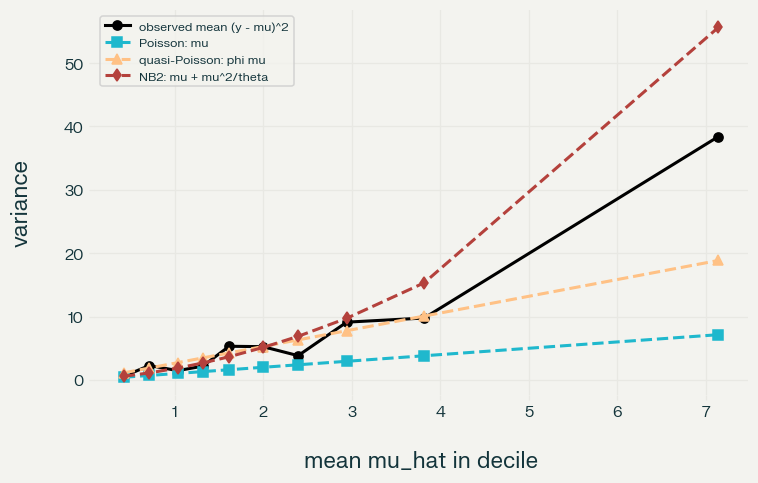


 customer_id    y    t  mu_hat  deviance resid  Pearson resid  NB2 Pearson  util  atm  visits  ln_inflow
        1478 25.0 26.0   7.639           4.956          6.281        2.439 0.590    6       1      4.672
        1592 18.0 35.0   4.651           4.692          6.189        2.707 0.293    5       5      5.387
        1399 14.0 21.0   3.126           4.498          6.150        3.442 0.650    6       3      5.744
        1324 10.0 24.0   1.624           4.427          6.573        4.191 0.264    4       0      5.209
        1086  7.0  9.0   0.764           4.306          7.134        4.992 0.036    8       2      4.739

Poisson |deviance resid| > 2: 119 (19.8%) | > 3: 26 (4.3%)
NB2 |Pearson resid| > 2: 32 (5.3%) | > 3: 12 (2.0%)
top five share of total deviance: 6.9%
zeros: observed 212 | Poisson expected 136.7 | NB2 expected 210.0
customers with |NB2 Pearson| > 3 among the top five: 3


In [ ]:
theta1 = theta
dec = pd.qcut(mu1, 10, labels=False) + 1
gd = pd.DataFrame({'dec': dec, 'y': yv, 'mu': mu1, 'sq': (yv - mu1) ** 2,
                   'nb': mu1 + mu1 ** 2 / theta1, 'quasi': phi1 * mu1})
T = gd.groupby('dec').agg(n=('y', 'size'), ybar=('y', 'mean'), mubar=('mu', 'mean'), mean_sq=('sq', 'mean'),
                          nb_var=('nb', 'mean'), quasi_var=('quasi', 'mean'), mu_low=('mu', 'min'), mu_high=('mu', 'max'))
print(T.round(3).to_string())
def rms_log(col):
    return float(np.sqrt(np.mean(np.log(T['mean_sq'] / T[col]) ** 2)))
print('\nRMS of log(observed / predicted variance): Poisson %.3f | quasi-Poisson %.3f | NB2 %.3f' % (rms_log('mubar'), rms_log('quasi_var'), rms_log('nb_var')))
print('max |ybar - mubar| over deciles = %.3f' % np.max(np.abs(T['ybar'] - T['mubar'])))
print('observed variance / mu_hat by decile:', (T['mean_sq'] / T['mubar']).round(2).tolist())
print('observed / quasi:', (T['mean_sq'] / T['quasi_var']).round(2).tolist())
print('observed / NB2:', (T['mean_sq'] / T['nb_var']).round(2).tolist())
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(T['mubar'], T['mean_sq'], 'ko-', label='observed mean (y - mu)^2')
ax.plot(T['mubar'], T['mubar'], 's--', label='Poisson: mu')
ax.plot(T['mubar'], T['quasi_var'], '^--', label='quasi-Poisson: phi mu')
ax.plot(T['mubar'], T['nb_var'], 'd--', label='NB2: mu + mu^2/theta')
ax.set_xlabel('mean mu_hat in decile'); ax.set_ylabel('variance'); ax.legend(fontsize=8)
show()

ylogy = np.where(yv > 0, yv * np.log(np.where(yv > 0, yv, 1) / mu1), 0.0)
dev_i = 2 * (ylogy - (yv - mu1))
rD = np.sign(yv - mu1) * np.sqrt(np.maximum(dev_i, 0))
rP = (yv - mu1) / np.sqrt(mu1)
assert np.isclose(np.sum(rD ** 2), pois.deviance) and np.isclose(np.sum(rP ** 2), X2_pois)
rP_nb = (yv - mu_nb) / np.sqrt(mu_nb + mu_nb ** 2 / theta)
top = np.argsort(-np.abs(rD))[:5]
topt = pd.DataFrame({'customer_id': d['customer_id'].to_numpy()[top], 'y': yv[top], 't': t1.to_numpy()[top], 'mu_hat': mu1[top],
                     'deviance resid': rD[top], 'Pearson resid': rP[top], 'NB2 Pearson': rP_nb[top],
                     'util': d['credit_utilization'].to_numpy()[top], 'atm': d['atm_withdrawals'].to_numpy()[top],
                     'visits': d['branch_visits'].to_numpy()[top], 'ln_inflow': d['ln_inflow'].to_numpy()[top]})
print()
print(topt.round(3).to_string(index=False))
print('\nPoisson |deviance resid| > 2: %d (%.1f%%) | > 3: %d (%.1f%%)' % ((np.abs(rD) > 2).sum(), 100 * (np.abs(rD) > 2).mean(), (np.abs(rD) > 3).sum(), 100 * (np.abs(rD) > 3).mean()))
print('NB2 |Pearson resid| > 2: %d (%.1f%%) | > 3: %d (%.1f%%)' % ((np.abs(rP_nb) > 2).sum(), 100 * (np.abs(rP_nb) > 2).mean(), (np.abs(rP_nb) > 3).sum(), 100 * (np.abs(rP_nb) > 3).mean()))
print('top five share of total deviance: %.1f%%' % (100 * dev_i[top].sum() / pois.deviance))
print('zeros: observed %d | Poisson expected %.1f | NB2 expected %.1f' % ((yv == 0).sum(), np.exp(-mu1).sum(), ((theta / (theta + mu_nb)) ** theta).sum()))
print('customers with |NB2 Pearson| > 3 among the top five:', int((np.abs(rP_nb[top]) > 3).sum()))

<div dir="rtl" style="text-align: right;">

میانگین مدل خوب است: میانگین y و میانگین mu_hat توی هر دهک نزدیک اند و بیشترین اختلاف 0.385 است. مشکل توی واریانس است. توی همه دهک ها واریانس مشاهده شده 1.4 تا 5.4 برابر mu_hat است، پس واریانس پواسون سازگار نیست. ریشه میانگین مربع لگاریتم نسبت برای پواسون 0.969 و برای شبه پواسون 0.435 و برای NB2 0.379 است. شبه پواسون توی دهک های پایین واریانس را بیش از حد برآورد می کند (نسبت 0.52 توی دهک 1) و توی دهک آخر کمتر از حد (نسبت 2.04)، یعنی واریانس سریع تر از خطی با mu بالا می رود. NB2 نزدیک ترین است ولی کامل نیست، توی دهک 2 کمتر برآورد می کند (نسبت 2.04) و توی دهک های 7 و 9 و 10 بیشتر (0.56 تا 0.69). هر دهک فقط 60 مشتری دارد و داده دم سنگین است، پس واریانس هر دهک نوفه ای است و تفاوت های دهک به دهک را نباید زیاد تفسیر کرد. نتیجه محتاطانه این است که NB2 از دو تابع دیگر سازگارتر است و این با AIC هم می خورد.

پنج مشتری با بزرگ ترین قدر مطلق باقی مانده انحراف، 1478 و 1592 و 1399 و 1324 و 1086 اند. همه شمارش بسیار بیشتر از پیش بینی دارند، مثلا 1086 هفت اضافه برداشت در 9 ماه دارد با mu_hat برابر 0.764 و credit_utilization برابر 0.036 که خیلی پایین است. این ها پرت منفرد نیستند و نشانه نقص مدل اند: 119 مشتری (19.8 درصد) قدر مطلق باقی مانده انحراف بیشتر از 2 دارند و 26 نفر بیشتر از 3، در حالی که اگر مدل درست بود حدود 5 درصد و 0.3 درصد انتظار می رفت. این پنج نفر فقط 6.9 درصد کل انحراف را می سازند. با NB2 باقی مانده پیرسون این پنج نفر از حدود 6 تا 7 به 2.4 تا 5.0 می رسد. دو نفر اول (2.44 و 2.71) به محدوده عادی نزدیک می شوند، ولی سه نفر 1399 و 1324 و 1086 (3.44 و 4.19 و 4.99) هنوز بالای 3 می مانند. توی کل داده هم با NB2 تعداد قدر مطلق بزرگ تر از 2 به 32 نفر (5.3 درصد) می رسد که نزدیک انتظار است، ولی 12 نفر (2.0 درصد) بزرگ تر از 3 اند، در حالی که حدود 0.3 درصد انتظار می رفت. پس NB2 نقص را خیلی کم می کند ولی کامل برطرف نمی کند.

پواسون صفرها را هم بد برآورد می کند: 212 صفر مشاهده شده و پواسون 136.7 انتظار دارد، ولی NB2 210.0. بررسی بیشتر سه مشتری بالا (1399 و 1324 و 1086) ارزش دارد، ولی با این داده نمی شود گفت اشتباه ثبت شده اند.

</div>

<div dir="rtl" style="text-align: right;">

### 8. سوال 1-ه (مفهومی)

### i) سازگاری پواسون و فرم ساندویچی

با offset، میانگین mu_i برابر t_i ضرب در e به توان x_i'beta است. تابع نمره پواسون برابر مجموع (y_i منهای mu_i(beta)) ضرب در x_i است. توی بتای واقعی امید این تابع صفر است و این فقط به این نیاز دارد که امید شرطی y_i برابر mu_i باشد، نه به برابری واریانس با میانگین. منفی لگاریتم درستنمایی اکیدا محدب است، پس ریشه معادله نمره یکتاست. با قانون اعداد بزرگ و این شرط که میانگین mu_i ضرب در x_i x_i' به یک ماتریس معین مثبت میل کند، برآورد به بتای واقعی میل می کند. یعنی سازگاری فقط با درستی مدل میانگین است.

با بسط تیلور، برآورد منهای بتای واقعی تقریبا برابر معکوس (X'WX) ضرب در تابع نمره است، که W قطری با درایه های mu_i است و به y بستگی ندارد. واریانس تابع نمره برابر مجموع Var(y_i) ضرب در x_i x_i' است. پس واریانس حدی به شکل ساندویچی درمی آید: معکوس (X'WX)، وسطش مجموع Var(y_i) ضرب در x_i x_i'، و دوباره معکوس (X'WX). برآورد HC0 به جای Var(y_i) مربع باقی مانده را می گذارد.

اگر Var(y_i) برابر phi ضرب در mu_i باشد، وسط ساندویچ برابر phi ضرب در (X'WX) می شود و کل واریانس به phi ضرب در معکوس (X'WX) فرو می ریزد. چون امید (y منهای mu) به توان 2 تقسیم بر mu برابر phi است، برآورد X2 تقسیم بر (n منهای p) برای phi سازگار است. پس خطای معیار شبه پواسون یعنی جذر phi_hat ضرب در خطای معیار پواسون درست است. روی همین داده نسبت HC0 به پواسون بین 1.74 و 1.89 بود، یعنی کمی بزرگ تر از جذر phi_hat که 1.62 است. این فقط نشانه ای است که واریانس شاید دقیقا ضربی در mu نباشد و با بخش د هم هم جهت است، ولی آزمون رسمی نیست.

### ii) NB2 و پیوند کانونی

برای theta معلوم، چگالی NB2 را می شود به شکل e به توان (y ضرب در لگاریتم mu بر (mu به اضافه theta) به اضافه theta ضرب در لگاریتم theta بر (mu به اضافه theta) به اضافه یک جمله که فقط به y و theta بستگی دارد) نوشت. پارامتر طبیعی اتا برابر لگاریتم mu بر (mu به اضافه theta) است که منفی است. چون theta بر (mu به اضافه theta) برابر یک منهای e به توان اتا می شود، تابع b برابر منفی theta ضرب در لگاریتم (یک منهای e به توان اتا) است. جمله آخر ربطی به mu ندارد، پس NB2 عضو خانواده نمایی است. مشتق اول b برابر mu و مشتق دومش برابر mu به اضافه mu به توان 2 بر theta است که تابع واریانس است. پیوند کانونی همین اتا است، یعنی لگاریتم mu بر (mu به اضافه theta).

لگاریتم mu برابر اتا به اضافه لگاریتم (mu به اضافه theta) است و جمله دوم ثابت نیست، پس پیوند لگاریتمی کانونی نیست. معادله نمره با پیوند لگاریتمی برابر مجموع (y_i منهای mu_i) تقسیم بر (1 به اضافه mu_i بر theta) ضرب در x_i است، چون مشتق mu_i نسبت به بتا برابر mu_i ضرب در x_i و تابع واریانس mu_i به اضافه mu_i به توان 2 بر theta است. برای ستون عرض از مبدا مجموع (y_i منهای mu_hat_i) تقسیم بر (1 به اضافه mu_hat_i بر theta) صفر است. وزن ها یکسان نیستند، پس لزوما مجموع y برابر مجموع mu_hat نیست. با پیوند کانونی، معادله نمره مجموع (y_i منهای mu_i) ضرب در x_i می شد و اتحاد برقرار می ماند. عددی چک می کنم.

</div>

In [ ]:
w_nb = 1 / (1 + mu_nb / theta)
print('NB2 (log link): sum y = %d | sum mu_hat = %.3f | difference = %.3f' % (yv.sum(), mu_nb.sum(), yv.sum() - mu_nb.sum()))
print('NB2 score for intercept: sum (y - mu)/(1 + mu/theta) = %.2e' % np.sum((yv - mu_nb) * w_nb))
print('max |X^T (y - mu) / (1 + mu/theta)| over all columns = %.2e' % np.abs(X1.to_numpy().T @ ((yv - mu_nb) * w_nb)).max())

NB2 (log link): sum y = 1405 | sum mu_hat = 1413.340 | difference = -8.340
NB2 score for intercept: sum (y - mu)/(1 + mu/theta) = 3.20e-14
max |X^T (y - mu) / (1 + mu/theta)| over all columns = 2.79e-12


<div dir="rtl" style="text-align: right;">

با NB2 و پیوند لگاریتمی مجموع y برابر 1405 و مجموع mu_hat برابر 1413.34 است (اختلاف منفی 8.34)، پس مجموع ها برابر نیستند. ولی مجموع وزن دار (y منهای mu_hat) تقسیم بر (1 به اضافه mu_hat بر theta) صفر است (حدود 1e-14)، که با معادله نمره می خواند.

### iii) آزمون مرزی H0: 1/theta = 0

فرض alpha برابر 1 بر theta. فضای پارامتر alpha بزرگ تر یا مساوی صفر است و فرض صفر روی مرز آن است. لگاریتم درستنمایی را حول alpha برابر صفر بسط می دهم. مشتق اول S برابر نصف مجموع ((y_i منهای mu_i) به توان 2 منهای y_i) است. این را عددی چک کردم و با مشتق عددی لگاریتم درستنمایی NB2 نزدیک صفر یکی بود. اطلاعات I برابر نصف مجموع mu_i به توان 2 است. تحت فرض صفر، Z برابر S بر جذر I به توزیع نرمال استاندارد میل می کند.

چون alpha نمی تواند منفی باشد، برآورد محدود شده برابر ماکسیمم صفر و S بر I است. پس آماره نسبت درستنمایی به مربع ماکسیمم صفر و Z میل می کند. این با احتمال نصف صفر است، وقتی Z منفی یا صفر باشد، و با احتمال نصف برابر Z به توان 2 با توزیع کای دو با یک درجه آزادی است. پس توزیع حدی آمیخته نصف کای دو با صفر درجه آزادی به اضافه نصف کای دو با یک درجه آزادی است، نه کای دو با یک درجه آزادی. p-value درست برابر نصف احتمال کای دو با یک درجه آزادی بزرگ تر از مقدار مشاهده شده است. روی داده آماره نسبت درستنمایی 393.79 است و p-value مرزی 6.2e-88 و p-value ساده 1.24e-87، که نتیجه را عوض نمی کند.

برای اینکه ببینم این تقریب مجانبی برای n برابر 600 چقدر خوب کار می کند، شبیه سازی کوچکی انجام دادم که پایین آمده است.

</div>

In [ ]:
rng = np.random.default_rng(SEED)
def prof_ll(ys, a):
    if a < 1e-9:
        g0 = sm.GLM(ys, X1, family=sm.families.Poisson(), offset=off1).fit()
        mg = np.asarray(g0.mu)
        return float(np.sum(ys * np.log(mg) - mg - special.gammaln(ys + 1)))
    th = 1 / a
    g1 = sm.GLM(ys, X1, family=sm.families.NegativeBinomial(alpha=a), offset=off1).fit()
    mg = np.asarray(g1.mu)
    return float(np.sum(special.gammaln(ys + th) - special.gammaln(th) - special.gammaln(ys + 1)
                        + th * np.log(th / (th + mg)) + ys * np.log(mg / (th + mg))))

res = minimize_scalar(lambda a: -prof_ll(yv, a), bounds=(1e-6, 3), method='bounded', options={'xatol': 1e-5})
lr_real = 2 * (-res.fun - prof_ll(yv, 0.0))
print('real data: constrained alpha_hat = %.4f, LRT = %.2f (NB2 fit gave %.2f)' % (res.x, lr_real, 2 * (nb.llf - pois.llf)))
print('boundary p = %.2e | plain chi2_1 p = %.2e' % (0.5 * stats.chi2.sf(lr_real, 1), stats.chi2.sf(lr_real, 1)))
S0 = 0.5 * np.sum((yv - mu1) ** 2 - yv)
I0 = 0.5 * np.sum(mu1 ** 2)
print('score at alpha = 0: S = %.1f, information I = %.1f, S / sqrt(I) = %.2f' % (S0, I0, S0 / np.sqrt(I0)))
def lognb(yy, mm, a):
    th = 1 / a
    return special.gammaln(yy + th) - special.gammaln(th) - special.gammaln(yy + 1) + th * np.log(th / (th + mm)) + yy * np.log(mm / (th + mm))
gap = 0.0
for _ in range(500):
    mm = rng.uniform(0.2, 10); yy = rng.integers(0, 30); a_ = 1e-5
    num = (lognb(yy, mm, 2 * a_) - lognb(yy, mm, a_)) / a_
    ana = 0.5 * ((yy - mm) ** 2 - yy)
    gap = max(gap, abs(num - ana) / (1 + abs(ana)))
print('max relative gap, numerical derivative at alpha ~ 0 vs 0.5*((y-mu)^2 - y): %.1e' % gap)
sim_lr = []
for s in range(250):
    ys = rng.poisson(mu1).astype(float)
    l0 = prof_ll(ys, 0.0)
    r_ = minimize_scalar(lambda a: -prof_ll(ys, a), bounds=(1e-6, 3), method='bounded', options={'xatol': 1e-4})
    sim_lr.append(2 * (max(-r_.fun, l0) - l0))
sim_lr = np.array(sim_lr)
R_ = len(sim_lr)
for nm, v, th_ in (('P(LRT ~ 0)', np.mean(sim_lr <= 0.01), 0.5), ('P(LRT > 2.706)', np.mean(sim_lr > 2.706), 0.05), ('P(LRT > 3.841)', np.mean(sim_lr > 3.841), 0.025)):
    print('simulation under H0 (%d samples): %s = %.3f (theory %.3f, Monte Carlo SE about %.3f)' % (R_, nm, v, th_, np.sqrt(th_ * (1 - th_) / R_)))

real data: constrained alpha_hat = 0.7797, LRT = 393.79 (NB2 fit gave 393.79)
boundary p = 6.20e-88 | plain chi2_1 p = 1.24e-87
score at alpha = 0: S = 1644.1, information I = 3046.7, S / sqrt(I) = 29.79
max relative gap, numerical derivative at alpha ~ 0 vs 0.5*((y-mu)^2 - y): 6.6e-04


simulation under H0 (250 samples): P(LRT ~ 0) = 0.676 (theory 0.500, Monte Carlo SE about 0.032)
simulation under H0 (250 samples): P(LRT > 2.706) = 0.028 (theory 0.050, Monte Carlo SE about 0.014)
simulation under H0 (250 samples): P(LRT > 3.841) = 0.020 (theory 0.025, Monte Carlo SE about 0.010)


<div dir="rtl" style="text-align: right;">

شبیه سازی تحت فرض صفر فقط 250 تکرار دارد، پس خطای مونت کارلو حدود 0.03 برای احتمال نزدیک نصف و حدود 0.01 برای احتمال های کوچک است. احتمال آماره حدود صفر 0.68 در آمد (نظریه 0.5) و احتمال بزرگ تر از 2.706 برابر 0.028 (نظریه 0.05). این به نظر می رسد تقریب آمیخته برای n برابر 600 و شمارش های کوچک محافظه کار باشد، ولی با 250 تکرار نمی شود قاطع گفت. در هر حال احتمال بزرگ تر از 2.706 با کای دو ساده 0.10 می شد، که با شبیه سازی خیلی فاصله دارد. توی داده ما آماره 393.79 است و تصمیم هیچ وقت عوض نمی شود. استدلال اصلی همان مجانبی است و این شبیه سازی فقط یک تذکر کوتاه است.

### 9. سوال 2: داده

فقط مشتری هایی را نگه می دارم که n_overdraft بیشتر از صفر دارند. n_i برابر n_overdraft و y_i برابر avg_overdraft_mrial است و وزن w_i برابر n_i است. بردار پیش بین هشت پارامتر دارد: عرض از مبدا و لگاریتم سقف اعتبار و لگاریتم کل واریزی و credit_utilization و age و لگاریتم هزینه کارتی و دو دامی Town و Rural با مبنای Metro. پس درجه آزادی باقی مانده n منهای 8 می شود.

</div>

In [ ]:
g = raw.loc[raw['n_overdraft'] > 0].copy().reset_index(drop=True)
g['w'] = g['n_overdraft'].astype(float)
y2 = g['avg_overdraft_mrial'].astype(float)
Xg = pd.DataFrame({'const': 1.0, 'ln_limit': np.log(g['credit_limit_mrial']), 'ln_inflow': np.log(g['total_inflow_mrial']),
                   'util': g['credit_utilization'], 'age': g['age'].astype(float), 'ln_card': np.log(g['card_spend_total_mrial']),
                   'Town': (g['branch_type'] == 'Town').astype(float), 'Rural': (g['branch_type'] == 'Rural').astype(float)})
n2, p2 = Xg.shape
w = g['w'].to_numpy()
y2v = y2.to_numpy()
assert n2 == 388 and p2 == 8 and y2.notna().all() and (y2 > 0).all()
print('n =', n2, '| p =', p2, '| residual df =', n2 - p2, '| sum of weights =', int(w.sum()))
print('branch_type:', g['branch_type'].value_counts().to_dict())
print('n_i distribution:', g['n_overdraft'].value_counts().sort_index().head(8).to_dict(), '... max', int(g['n_overdraft'].max()))
grp = pd.cut(g['n_overdraft'], [0, 1, 3, 100], labels=['n=1', 'n in {2,3}', 'n>=4'])
print('groups:', grp.value_counts().sort_index().to_dict())

n = 388 | p = 8 | residual df = 380 | sum of weights = 1405
branch_type: {'Metro': 187, 'Town': 143, 'Rural': 58}
n_i distribution: {1: 131, 2: 73, 3: 49, 4: 41, 5: 21, 6: 24, 7: 10, 8: 8} ... max 30
groups: {'n=1': 131, 'n in {2,3}': 122, 'n>=4': 135}


<div dir="rtl" style="text-align: right;">

388 مشتری می ماند: Metro برابر 187 و Town برابر 143 و Rural برابر 58. مجموع وزن ها 1405 است که همان کل اضافه برداشت هاست. سه گروه سوال د: 131 نفر با n برابر 1 و 122 نفر با n در {2,3} و 135 نفر با n بزرگ تر یا مساوی 4.

### 10. سوال 2-الف: توصیف y و مدل ها

میانگین و انحراف معیار و چولگی و ضریب تغییرات y و چولگی لگاریتم y را می نویسم. بعد مدل خطی گاوسی را یک بار روی y و یک بار روی لگاریتم y برازش می دهم و R2 و آزمون Breusch-Pagan را می نویسم. آزمون Breusch-Pagan را هم با نسخه پیش فرض statsmodels که Koenker است و هم با نسخه اصلی می زنم، چون نسخه اصلی نرمال بودن خطا را فرض می کند. بعد مدل گامای وزن دار را با پیوند لگاریتمی و var_weights برابر n_i برازش می دهم.

</div>

In [ ]:
ly = np.log(y2)
print('y:    mean %.3f | sd %.3f | median %.3f | skewness %.3f | CV %.3f | min %.3f | max %.3f' % (
    y2.mean(), y2.std(ddof=1), y2.median(), stats.skew(y2), y2.std(ddof=1) / y2.mean(), y2.min(), y2.max()))
print('ln y: mean %.3f | sd %.3f | skewness %.4f | excess kurtosis %.3f | Shapiro p = %.3f' % (
    ly.mean(), ly.std(ddof=1), stats.skew(ly), stats.kurtosis(ly), stats.shapiro(ly).pvalue))
lin = {}
for name, resp in (('y', y2), ('ln y', ly)):
    o = sm.OLS(resp, Xg).fit()
    lm_k, p_k, _, _ = het_breuschpagan(o.resid, Xg)
    lm_o, p_o, _, _ = het_breuschpagan(o.resid, Xg, robust=False)
    lin[name] = o
    print('OLS on %-4s: R2 %.4f | adj R2 %.4f | BP Koenker LM = %.2f (p = %.2e) | BP original LM = %.2f (p = %.2e)' % (name, o.rsquared, o.rsquared_adj, lm_k, p_k, lm_o, p_o))
ols_ln = lin['ln y']
r = ols_ln.resid.to_numpy()
tb = pd.DataFrame({'group': grp.values, 'sq': r ** 2}).groupby('group').agg(n=('sq', 'size'), mean_sq_resid=('sq', 'mean'))
print()
print(tb.round(4).to_string())
fit_1n = sm.OLS(r ** 2, sm.add_constant(1 / w)).fit()
print('squared residual ~ a + b/n_i: b = %.4f (p = %.2e), R2 = %.3f' % (fit_1n.params[1], fit_1n.pvalues[1], fit_1n.rsquared))

fam = sm.families.Gamma(sm.families.links.Log())
gam = sm.GLM(y2, Xg, family=fam, var_weights=g['w']).fit()
mu2 = np.asarray(gam.mu)
X2_g = float(np.sum(w * (y2v - mu2) ** 2 / mu2 ** 2))
phi2 = X2_g / (n2 - p2)
dev_g = 2 * float(np.sum(w * ((y2v - mu2) / mu2 - np.log(y2v / mu2))))
null_g = sm.GLM(y2, np.ones((n2, 1)), family=fam, var_weights=g['w']).fit()
assert np.isclose(dev_g, gam.deviance) and np.isclose(phi2, gam.scale)
print('\nGamma (weighted): deviance %.4f on %d df | null deviance %.4f on %d df | X2 = %.4f | phi_hat = %.4f (shape 1/phi = %.3f)' % (
    gam.deviance, n2 - p2, null_g.deviance, n2 - 1, X2_g, phi2, 1 / phi2))
tab_g = pd.DataFrame({'coef': gam.params, 'SE': gam.bse, 't': gam.tvalues, 'p': gam.pvalues, 'exp(coef)': np.exp(gam.params),
                      'OLS ln y coef': ols_ln.params, 'OLS SE': ols_ln.bse, 'OLS p': ols_ln.pvalues, 'SE OLS / SE gamma': ols_ln.bse / gam.bse})
print(tab_g.round(4).to_string())
bg, bo = gam.params, ols_ln.params
print('\nmultiplicative effects (gamma | OLS ln y): ln_limit +1%%: %.4f | %.4f ; ln_inflow +1%%: %.4f | %.4f ; ln_card +1%%: %.4f | %.4f ; util +0.1: %.4f | %.4f ; age +10y: %.4f | %.4f ; Town: %.3f | %.3f ; Rural: %.3f | %.3f' % (
    1.01 ** bg['ln_limit'], 1.01 ** bo['ln_limit'], 1.01 ** bg['ln_inflow'], 1.01 ** bo['ln_inflow'], 1.01 ** bg['ln_card'], 1.01 ** bo['ln_card'],
    np.exp(0.1 * bg['util']), np.exp(0.1 * bo['util']), np.exp(10 * bg['age']), np.exp(10 * bo['age']), np.exp(bg['Town']), np.exp(bo['Town']), np.exp(bg['Rural']), np.exp(bo['Rural'])))

y:    mean 22.819 | sd 24.128 | median 15.992 | skewness 3.743 | CV 1.057 | min 0.934 | max 242.757
ln y: mean 2.757 | sd 0.860 | skewness -0.0001 | excess kurtosis 0.118 | Shapiro p = 0.997
OLS on y   : R2 0.5013 | adj R2 0.4921 | BP Koenker LM = 32.15 (p = 3.81e-05) | BP original LM = 472.20 (p = 7.56e-98)
OLS on ln y: R2 0.6999 | adj R2 0.6943 | BP Koenker LM = 38.61 (p = 2.32e-06) | BP original LM = 69.23 (p = 2.11e-12)

              n  mean_sq_resid
group                         
n=1         131         0.3882
n in {2,3}  122         0.2082
n>=4        135         0.0715
squared residual ~ a + b/n_i: b = 0.3763 (p = 1.48e-10), R2 = 0.101

Gamma (weighted): deviance 153.0238 on 380 df | null deviance 891.7967 on 387 df | X2 = 153.4323 | phi_hat = 0.4038 (shape 1/phi = 2.477)
             coef      SE        t       p  exp(coef)  OLS ln y coef  OLS SE   OLS p  SE OLS / SE gamma
const     -4.2757  0.2074 -20.6161  0.0000     0.0139        -4.4881  0.3117  0.0000             1.5028
l

<div dir="rtl" style="text-align: right;">

میانگین y برابر 22.819 و انحراف معیار 24.128 و میانه 15.992 است و دامنه از 0.934 تا 242.757. ضریب تغییرات 1.057 و چولگی 3.743 است، یعنی y خیلی چوله راست است. چولگی لگاریتم y تقریبا صفر است (منفی 0.0001) و آزمون Shapiro هم نرمال بودن را رد نمی کند (p برابر 0.997). یعنی لگاریتم y تقریبا نرمال است.

مدل خطی روی y مقدار R2 برابر 0.5013 و روی لگاریتم y برابر 0.6999 دارد. این دو روی مقیاس های مختلف اند و قابل مقایسه نیستند. آزمون Breusch-Pagan توی هر دو معنادار است: روی y با نسخه Koenker آماره 32.15 و p برابر 3.8e-5 و نسخه اصلی 472.2 و p برابر 7.6e-98، و روی لگاریتم y آماره 38.61 با p برابر 2.3e-6 و نسخه اصلی 69.23. نسخه اصلی با y چوله خیلی بزرگ می شود، چون نرمال بودن خطا را فرض می کند. حتی روی لگاریتم y ناهمسانی هست و منبعش روشن است: میانگین مربع باقی مانده با بزرگ شدن n_i کم می شود، 0.388 برای n برابر 1 و 0.208 برای n توی {2,3} و 0.072 برای n بزرگ تر یا مساوی 4. رگرسیون مربع باقی مانده روی یک بر n_i شیب 0.376 با p برابر 1.5e-10 می دهد. این همان ساختار واریانس متناسب با یک بر n_i در مدل گاماست.

مدل گامای وزن دار انحراف 153.02 با 380 درجه آزادی و انحراف مدل تهی 891.80 دارد. آماره پیرسون 153.43 و phi_hat برابر 0.4038 است. یعنی شکل برابر 2.48 و ضریب تغییر یک رویداد منفرد جذر 0.4038 یعنی 0.635. مثل قبل انحراف دستی با کتابخانه یکی است.

سه ضریب اول معنادارند: لگاریتم سقف اعتبار 0.6896 و لگاریتم کل واریزی 0.7080 و credit_utilization برابر 1.2123. لگاریتم سقف و لگاریتم واریزی کشش اند، یعنی یک درصد سقف بیشتر شدت اضافه برداشت را 1.0069 برابر می کند و یک درصد واریزی بیشتر 1.0071 برابر. 0.1 افزایش credit_utilization آن را 1.129 برابر می کند. age (منفی 0.0003 با p برابر 0.84) و لگاریتم هزینه کارتی (منفی 0.0565 با p برابر 0.147) و Town (0.0409) و Rural (0.0486) اثر قابل تشخیصی ندارند. Town و Rural نسبت به Metro 1.042 و 1.050 برابراند ولی معنادار نیستند.

با مدل خطی روی لگاریتم y علامت ها و معناداری یکی است و ضرایب نزدیک اند، بزرگ ترین اختلاف credit_utilization با 1.4511 در برابر 1.2123 است که اثر ضربی 0.1 واحد را 1.156 در برابر 1.129 می کند. خطای معیار OLS بین 1.37 تا 1.57 برابر خطای گاماست، چون OLS ناهمسانی را نادیده می گیرد و به مشتری با یک رویداد همان وزن مشتری با ده رویداد را می دهد. تفسیر هم کمی فرق دارد: گاما لگاریتم میانگین را مدل می کند و OLS میانگین لگاریتم را، و این دو به خاطر نابرابری ینسن برابر نیستند.

</div>

<div dir="rtl" style="text-align: right;">

### 11. سوال 2-ب: آزمون چهار ضریب

فرض این است که ضریب age و لگاریتم هزینه کارتی و Town و Rural همه صفرند. مدل کوچک تر فقط عرض از مبدا و لگاریتم سقف و لگاریتم واریزی و credit_utilization را دارد، پس q برابر 4 و درجه آزادی باقی مانده مدل بزرگ تر 380 است. تفاضل انحراف ها را بر phi_hat مدل بزرگ تر تقسیم می کنم و با کای دو مقایسه می کنم و F را هم می نویسم. آزمون Wald مشترک را هم کنارش چک می کنم.

</div>

In [ ]:
small2 = ['const', 'ln_limit', 'ln_inflow', 'util']
g0 = sm.GLM(y2, Xg[small2], family=fam, var_weights=g['w']).fit()
q2 = p2 - len(small2)
dD2 = g0.deviance - gam.deviance
chi_s = dD2 / phi2
F_s = (dD2 / q2) / phi2
print('q = %d | D0 = %.4f (df %d) | D1 = %.4f (df %d) | delta D = %.4f | phi_hat (large) = %.4f' % (q2, g0.deviance, n2 - len(small2), gam.deviance, n2 - p2, dD2, phi2))
print('delta D / phi_hat = %.3f ~ chi2(%d): p = %.3f' % (chi_s, q2, stats.chi2.sf(chi_s, q2)))
print('F = (delta D / q) / phi_hat = %.3f ~ F(%d, %d): p = %.3f' % (F_s, q2, n2 - p2, stats.f.sf(F_s, q2, n2 - p2)))
four = ['age', 'ln_card', 'Town', 'Rural']
ii = [list(gam.params.index).index(c) for c in four]
bb = gam.params.to_numpy()[ii]
V = gam.cov_params().to_numpy()[np.ix_(ii, ii)]
wald4 = float(bb @ np.linalg.solve(V, bb))
print('joint Wald = %.3f | Wald/q = %.3f ~ F(%d, %d): p = %.3f' % (wald4, wald4 / q2, q2, n2 - p2, stats.f.sf(wald4 / q2, q2, n2 - p2)))
print('individual t values:', gam.tvalues[four].round(2).to_dict())

q = 4 | D0 = 154.5094 (df 384) | D1 = 153.0238 (df 380) | delta D = 1.4857 | phi_hat (large) = 0.4038
delta D / phi_hat = 3.679 ~ chi2(4): p = 0.451
F = (delta D / q) / phi_hat = 0.920 ~ F(4, 380): p = 0.452
joint Wald = 3.697 | Wald/q = 0.924 ~ F(4, 380): p = 0.450
individual t values: {'age': -0.2, 'ln_card': -1.45, 'Town': 1.09, 'Rural': 0.98}


<div dir="rtl" style="text-align: right;">

تفاضل انحراف 1.4857 است (154.5094 با 384 درجه آزادی برای مدل کوچک تر و 153.0238 با 380 برای مدل بزرگ تر). تقسیم بر phi_hat برابر 0.4038 آماره 3.679 می دهد و با مرجع کای دو و چهار درجه آزادی p برابر 0.451 می شود. آماره F برابر 0.920 با 4 و 380 درجه آزادی و p برابر 0.452 است. آزمون Wald مشترک هم 0.924 (بعد از تقسیم بر 4) و p برابر 0.450 می دهد. فرض صفر رد نمی شود، یعنی شواهد کافی نداریم که این چهار متغیر با هم چیزی به مدل اضافه کنند. این با t های جدا هم می خواند که همه قدر مطلق کمتر از 1.45 اند. رد نشدن اثبات بی اثری نیست و با 388 مشتری فقط اثرهای بزرگ تر قابل تشخیص اند. دو p-value تقریبا یکی اند چون درجه آزادی 380 بزرگ است و F به کای دو نزدیک می شود.

### 12. سوال 2-ج: اتحاد گاما و چهار روش نسبت کل

لگاریتم درستنمایی گاما تا جمله های بدون mu برابر یک بر phi ضرب در مجموع w_i ضرب در (منفی y_i بر mu_i منهای لگاریتم mu_i) است. با پیوند لگاریتمی مشتق mu_i نسبت به بتا برابر mu_i ضرب در x_i است. پس مشتق لگاریتم درستنمایی نسبت به بتا برابر یک بر phi ضرب در مجموع w_i ضرب در (y_i بر mu_i منهای 1) ضرب در x_i می شود که همان مجموع w_i ضرب در (y_i منهای mu_i) بر mu_i ضرب در x_i است. ستون عرض از مبدا همه اش 1 است، پس مجموع w_i ضرب در (y_i منهای mu_hat_i) بر mu_hat_i برابر صفر است. این با مجموع w_i ضرب در (y_i منهای mu_hat_i) فرق دارد، چون هر جمله تقسیم بر mu_hat_i شده و وزن ها یکسان نیستند. در پواسون با پیوند لگاریتمی کانونی معادله نمره مجموع (y_i منهای mu_i) ضرب در x_i بود و اتحاد برقرار می ماند.

بعد نسبت مجموع w_i ضرب در mu_hat_i به مجموع w_i ضرب در y_i را با چهار روش حساب می کنم. توی صورت سوال روش ها حرف ندارند و فقط تیک خورده اند، پس به ترتیب شان می خوانم: روش اول گاما با پیوند لگاریتمی که mu_hat را از مدل گاما می گیرد، و سه روش دیگر از مدل خطی روی لگاریتم y با مقدار برازش شده اتا، باقی مانده ها e و واریانس باقی مانده سیگما به توان 2: روش دوم برگرداندن ساده e به توان اتا، روش سوم اصلاح Duan با ضرب در میانگین e به توان باقی مانده ها، و روش چهارم اصلاح نرمال با e به توان (اتا به اضافه سیگما به توان 2 بر 2). «(ب)» توی سوال را همان روش دوم گرفتم. برای سیگما به توان 2 مقدار RSS تقسیم بر (n منهای p) را گذاشتم.

</div>

In [ ]:
print('identity: sum w (y - mu)/mu = %.2e | sum w y = %.3f | sum w mu = %.3f | difference = %.3f' % (
    np.sum(w * (y2v - mu2) / mu2), np.sum(w * y2v), np.sum(w * mu2), np.sum(w * y2v) - np.sum(w * mu2)))
print('all score equations: max |X^T w (y - mu)/mu| = %.2e' % np.abs(Xg.to_numpy().T @ (w * (y2v - mu2) / mu2)).max())
eta = np.asarray(ols_ln.fittedvalues)
e_hat = np.asarray(ols_ln.resid)
s2 = ols_ln.mse_resid
duan = np.mean(np.exp(e_hat))
meth = {'1 gamma, log link': mu2, '2 simple exp(eta)': np.exp(eta), '3 Duan smearing': np.exp(eta) * duan, '4 normal correction': np.exp(eta + s2 / 2)}
tot_y = np.sum(w * y2v)
print('Duan factor = %.4f | exp(sigma2/2) = %.4f (sigma2 = %.4f)' % (duan, np.exp(s2 / 2), s2))
ratio = pd.DataFrame({'sum w mu_hat': {k: np.sum(w * v) for k, v in meth.items()}, 'ratio': {k: np.sum(w * v) / tot_y for k, v in meth.items()}})
print('observed sum w y = %.1f' % tot_y)
print(ratio.round(4).to_string())
print('expected ratio of method 2 if one global sigma2 applied: 1/exp(sigma2/2) = %.4f' % (1 / np.exp(s2 / 2)))
byg = pd.DataFrame({k: pd.Series(w * v).groupby(grp.values).sum() / pd.Series(w * y2v).groupby(grp.values).sum() for k, v in meth.items()})
byg['share of total weight'] = pd.Series(w).groupby(grp.values).sum() / w.sum()
print()
print(byg.round(3).to_string())
print('mean OLS residual by group:', pd.Series(e_hat).groupby(grp.values).mean().round(3).to_dict())
print('residual variance by group:', pd.Series(e_hat).groupby(grp.values).var().round(3).to_dict())
print('group-wise Duan factors:', {str(l): round(float(np.mean(np.exp(e_hat[(grp == l).to_numpy()]))), 3) for l in grp.cat.categories})
sm_g = np.zeros(n2)
for lab in grp.cat.categories:
    ix = (grp == lab).to_numpy()
    sm_g[ix] = np.mean(np.exp(e_hat[ix]))
print('ratio with group-wise smearing = %.4f' % (np.sum(w * np.exp(eta) * sm_g) / tot_y))

identity: sum w (y - mu)/mu = 7.76e-13 | sum w y = 30220.695 | sum w mu = 30039.490 | difference = 181.205
all score equations: max |X^T w (y - mu)/mu| = 2.62e-10
Duan factor = 1.1100 | exp(sigma2/2) = 1.1197 (sigma2 = 0.2261)
observed sum w y = 30220.7
                     sum w mu_hat   ratio
1 gamma, log link      30039.4905  0.9940
2 simple exp(eta)      27830.9758  0.9209
3 Duan smearing        30891.2952  1.0222
4 normal correction    31161.5756  1.0311
expected ratio of method 2 if one global sigma2 applied: 1/exp(sigma2/2) = 0.8931

            1 gamma, log link  2 simple exp(eta)  3 Duan smearing  4 normal correction  share of total weight
n=1                     0.970              0.871            0.967                0.975                  0.093
n in {2,3}              0.958              0.879            0.976                0.985                  0.209
n>=4                    1.010              0.943            1.047                1.056                  0.698
mean OLS resi

<div dir="rtl" style="text-align: right;">

مجموع w_i ضرب در (y_i منهای mu_hat_i) بر mu_hat_i برابر 7.8e-13 یعنی صفر است. ولی مجموع w_i ضرب در y_i برابر 30220.7 و مجموع w_i ضرب در mu_hat_i برابر 30039.5 است، یعنی اختلاف 181.2 (حدود 0.6 درصد). همه معادله های نمره هم تا حدود 3e-10 صفرند.

نسبت ها برای روش گاما 0.9940 و برای برگرداندن ساده 0.9209 و برای Duan 1.0222 و برای نرمال 1.0311 است. ضریب Duan برابر 1.1100 و ضریب نرمال 1.1197 است.

با نابرابری ینسن، تابع نمایی محدب است، پس امید e به توان (لگاریتم y) بیشتر از e به توان امید لگاریتم y است. e به توان اتا_hat برآورد میانگین هندسی یا میانه است، نه میانگین حسابی، پس مجموع آن از کل مشاهده شده کمتر می شود. اگر لگاریتم y برابر اتا به اضافه خطای نرمال با واریانس سیگما به توان 2 باشد، میانگین y برابر e به توان (اتا به اضافه سیگما به توان 2 بر 2) است که از e به توان اتا بیشتر است. با سیگما به توان 2 برابر 0.2261 انتظار می رود نسبت حدود 0.893 باشد و نسبت واقعی 0.921 است. یک توضیح محتمل برای این اختلاف ناهمسانی است: واریانس باقی مانده با n_i کم می شود و 70 درصد وزن کل مال گروه n بزرگ تر یا مساوی 4 است که واریانس کوچک تری دارد، پس اثر ینسن توی جمع وزن دار از اثر یک سیگمای سراسری کمتر است.

Duan و نرمال کمی از 1 بالاترند. به نظر می رسد ضریب سراسری 1.11 برای گروه سنگین وزن n بزرگ تر یا مساوی 4 زیادی بزرگ است. نسبت آن گروه 1.047 و 1.056 می شود، در حالی که برای گروه n برابر 1 نسبت ها 0.967 و 0.975 اند. با ضریب Duan جدا برای هر گروه (1.100 و 1.140 و 1.092) نسبت کل به 1.017 می رسد. میانگین باقی مانده OLS هم بین گروه ها فرق دارد (منفی 0.084 و 0.028 و 0.056)، که با نظریه گاما هم جهت است: برای میانگین n_i رویداد میانگین لگاریتم برابر دیگاما(n_i ضرب در نو) منهای لگاریتم (n_i ضرب در نو) به اضافه لگاریتم mu است و جمله اول با n_i بالا می رود. روش گاما از همه به 1 نزدیک تر است و هر دو اثر را از خود مدل می گیرد. 0.6 درصد کسری اش طبیعی است، چون فقط مجموع وزن دار نسبت ها صفر تضمین شده است، نه مجموع w_i ضرب در mu_hat_i برابر مجموع w_i ضرب در y_i.

### 13. سوال 2-د (مفهومی)

### i) میانگین گاماهای مستقل

فرض می کنم Z_i1 تا Z_in_i مستقل و گاما با شکل nu و میانگین m باشند. تابع مولد گشتاور هر کدام (یک منهای s ضرب در m بر nu) به توان منفی nu است. مجموع n_i تا از آنها تابع مولدش همین عبارت به توان n_i است، یعنی (یک منهای s ضرب در m بر nu) به توان منفی n_i ضرب در nu. میانگین مجموع تقسیم بر n_i است، پس s را با s بر n_i عوض می کنم و به (یک منهای s ضرب در m بر (n_i ضرب در nu)) به توان منفی n_i ضرب در nu می رسم. این تابع مولد گامای با شکل n_i ضرب در nu و میانگین m است. یکتایی تابع مولد نتیجه می دهد میانگین y_i گامای با شکل n_i ضرب در nu و میانگین m است. واریانس گاما با شکل kappa و میانگین m برابر m به توان 2 بر kappa است، پس Var(y_i) برابر m به توان 2 بر (n_i ضرب در nu) می شود. اگر phi برابر یک بر nu باشد، این برابر phi ضرب در m به توان 2 بر n_i است. یعنی وزن پیشین w_i برابر n_i است.

### ii) وزن IRLS و اطلاعات فیشر

با پیوند لگاریتمی g(mu) برابر لگاریتم mu است و مشتقش یک بر mu است. تابع واریانس V(mu) برابر mu به توان 2 است و واریانس هر مشاهده V(mu_i) بر w_i ضرب در phi است. وزن کاری IRLS برابر یک بر ((V(mu_i) بر w_i) ضرب در (مشتق g) به توان 2) است، یعنی یک بر ((mu_i به توان 2 بر w_i) ضرب در (یک بر mu_i به توان 2)) که برابر w_i می شود. به mu_i بستگی ندارد، در حالی که در پواسون وزن برابر mu_i بود. عددی چک شد و وزن های کاری دقیقا برابر w_i اند.

اطلاعات فیشر یک بر phi ضرب در X' diag(w_i) X است و به بتا هم بستگی ندارد. اطلاعات مشاهده شده یک بر phi ضرب در مجموع w_i ضرب در y_i بر mu_i ضرب در x_i x_i' است که به y بستگی دارد، ولی چون امید y_i بر mu_i برابر 1 است، امیدش همان اطلاعات فیشر است. روی داده فاصله این دو ماتریس در نرم فروبنیوس فقط 0.09 درصد است.

برآورد بتا به phi بستگی ندارد چون معادله نمره یک بر phi ضرب در مجموع w_i ضرب در (y_i منهای mu_i) بر mu_i ضرب در x_i است و phi ضریب کل معادله است و حذف می شود. توی IRLS هم X'WX و X'Wz هر دو یک بر phi دارند و توی حاصل ضرب ساده می شوند. phi فقط توی کواریانس می آید که phi ضرب در معکوس X' diag(w_i) X است. عددی چک می کنم.

</div>

In [ ]:
gam_u = sm.GLM(y2, Xg, family=fam).fit()
mu_u = np.asarray(gam_u.mu)
phi_u = float(np.sum((y2v - mu_u) ** 2 / mu_u ** 2) / (n2 - p2))
iw = (mu2 ** 2) / ((mu2 ** 2) / w)
print('IRLS working weights equal w_i exactly:', np.allclose(iw, w))
I_f = (Xg.to_numpy().T @ (Xg.to_numpy() * w[:, None])) / phi2
I_o = (Xg.to_numpy().T @ (Xg.to_numpy() * (w * y2v / mu2)[:, None])) / phi2
print('phi * I^-1 equals statsmodels covariance: max diff %.1e' % np.abs(np.linalg.inv(I_f) - gam.cov_params().to_numpy()).max())
print('observed vs expected information, relative Frobenius difference: %.4f' % (np.linalg.norm(I_o - I_f) / np.linalg.norm(I_f)))
gam7 = sm.GLM(y2, Xg, family=fam, var_weights=g['w'] * 7.0).fit()
print('all weights x7: max coefficient change %.1e | phi_hat %.4f (was %.4f) | SE ratio %.3f' % (np.abs(gam7.params - gam.params).max(), gam7.scale, phi2, (gam7.bse / gam.bse).mean()))

IRLS working weights equal w_i exactly: True
phi * I^-1 equals statsmodels covariance: max diff 4.6e-16
observed vs expected information, relative Frobenius difference: 0.0009
all weights x7: max coefficient change 6.2e-15 | phi_hat 2.8264 (was 0.4038) | SE ratio 1.000


<div dir="rtl" style="text-align: right;">

اگر همه وزن ها را 7 برابر کنم، ضرایب تا 1e-14 همان می مانند، phi_hat هفت برابر می شود (2.8264) و خطاهای معیار تغییری نمی کنند. این همان است که انتظار داشتم.

### iii) وزن دار در برابر بدون وزن

مدل گاما را یک بار با وزن n_i و یک بار بدون وزن برازش می دهم و ضرایب و خطاها و phi_hat را کنار هم می گذارم. بعد مشتری ها را در سه گروه می گذارم و میانگین مربع باقی مانده پیرسون مقیاس شده را برای هر دو مدل می نویسم: برای مدل وزن دار جذر w_i ضرب در (y_i منهای mu_hat_i) بر mu_hat_i و برای مدل بدون وزن (y_i منهای mu_hat_i) بر mu_hat_i. mu_hat هر مدل را از خود همان مدل می گیرم.

</div>

phi_hat: weighted 0.4038 | unweighted 0.2093
           coef weighted  SE weighted  coef unweighted  SE unweighted  diff (U - W)  diff / SE weighted  SE U / SE W  p weighted  p unweighted
const            -4.2757       0.2074          -4.6748         0.2999       -0.3992             -1.9247       1.4459      0.0000        0.0000
ln_limit          0.6896       0.0344           0.7224         0.0458        0.0328              0.9548       1.3345      0.0000        0.0000
ln_inflow         0.7080       0.0480           0.7601         0.0724        0.0522              1.0860       1.5064      0.0000        0.0000
util              1.2123       0.0944           1.2440         0.1379        0.0316              0.3347       1.4605      0.0000        0.0000
age              -0.0003       0.0017           0.0013         0.0022        0.0017              0.9957       1.3173      0.8381        0.5480
ln_card          -0.0565       0.0389          -0.0898         0.0541       -0.0333             -

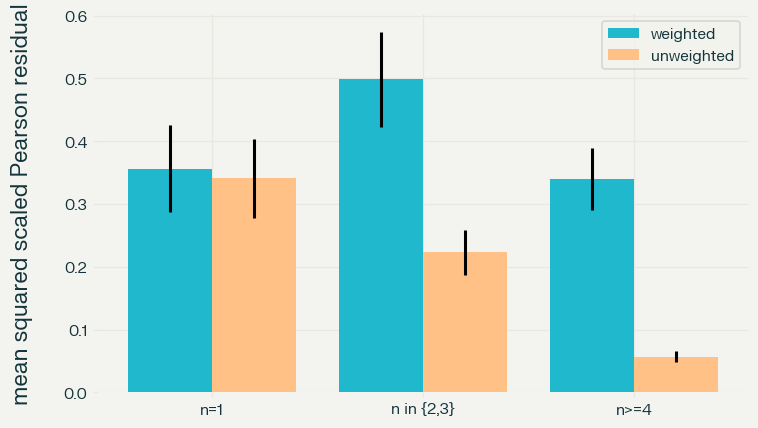

In [ ]:
cmp_w = pd.DataFrame({'coef weighted': gam.params, 'SE weighted': gam.bse, 'coef unweighted': gam_u.params, 'SE unweighted': gam_u.bse})
cmp_w['diff (U - W)'] = cmp_w['coef unweighted'] - cmp_w['coef weighted']
cmp_w['diff / SE weighted'] = cmp_w['diff (U - W)'] / cmp_w['SE weighted']
cmp_w['SE U / SE W'] = cmp_w['SE unweighted'] / cmp_w['SE weighted']
cmp_w['p weighted'] = gam.pvalues
cmp_w['p unweighted'] = gam_u.pvalues
print('phi_hat: weighted %.4f | unweighted %.4f' % (phi2, phi_u))
print(cmp_w.round(4).to_string())
rw = np.sqrt(w) * (y2v - mu2) / mu2
ru = (y2v - mu_u) / mu_u
tab_r = pd.DataFrame({'count': grp.value_counts().sort_index(),
                      'weighted mean r2': pd.Series(rw ** 2).groupby(grp.values).mean(),
                      'unweighted mean r2': pd.Series(ru ** 2).groupby(grp.values).mean(),
                      'mean 1/n': pd.Series(1 / w).groupby(grp.values).mean()})
tab_r['phi_weighted * mean(1/n)'] = phi2 * tab_r['mean 1/n']
tab_r['SE weighted'] = pd.Series(rw ** 2).groupby(grp.values).std() / np.sqrt(tab_r['count'])
tab_r['SE unweighted'] = pd.Series(ru ** 2).groupby(grp.values).std() / np.sqrt(tab_r['count'])
print()
print(tab_r.round(4).to_string())
for name, rr in (('weighted', rw), ('unweighted', ru)):
    o = sm.OLS(rr ** 2, sm.add_constant(1 / w)).fit()
    kw = stats.kruskal(*[rr[(grp == l).to_numpy()] ** 2 for l in grp.cat.categories])
    print('%s: r2 ~ a + b/n -> b = %.4f (p = %.2e) | Kruskal-Wallis across groups p = %.2e' % (name, o.params[1], o.pvalues[1], kw.pvalue))
fig, ax = plt.subplots(figsize=(7, 4))
xs = np.arange(3)
ax.bar(xs - 0.2, tab_r['weighted mean r2'], 0.4, yerr=tab_r['SE weighted'], label='weighted')
ax.bar(xs + 0.2, tab_r['unweighted mean r2'], 0.4, yerr=tab_r['SE unweighted'], label='unweighted')
ax.set_xticks(xs); ax.set_xticklabels(tab_r.index); ax.set_ylabel('mean squared scaled Pearson residual'); ax.legend()
show()

<div dir="rtl" style="text-align: right;">

phi_hat مدل وزن دار 0.4038 و مدل بدون وزن 0.2093 است. ضرایب جز عرض از مبدا در حدود یک خطای معیار هم اند و معناداری یکی است: سه متغیر اول معنادارند و بقیه نه. عرض از مبدا از منفی 4.276 به منفی 4.675 می رود که 1.92 خطای معیار وزن دار است. خطای معیار مدل بدون وزن 1.32 تا 1.51 برابر بزرگ تر است. phi_hat دو مدل قابل مقایسه نیستند، چون توی مدل بدون وزن phi_hat میانگینی از واریانس هاست که با n_i عوض می شوند.

میانگین مربع باقی مانده پیرسون مقیاس شده توی مدل وزن دار برای سه گروه 0.356 و 0.499 و 0.340 است، یعنی توی هر سه گروه حدود phi_hat برابر 0.40 می ماند. گروه میانی کمی بالاتر است ولی تفاوت میان گروه ها معنادار نیست (آزمون Kruskal-Wallis با p برابر 0.123 و شیب رگرسیون روی یک بر n برابر منفی 0.022 با p برابر 0.84). توی مدل بدون وزن مقدارها 0.341 و 0.223 و 0.057 اند، یعنی حدود شش برابر کم می شود (Kruskal-Wallis با p برابر 2.3e-13 و شیب روی یک بر n برابر 0.328 با p برابر 2.6e-6). ستون phi ضرب در میانگین یک بر n هم همین جهت را دارد. پس ساختار واریانس phi ضرب در mu به توان 2 بر n_i با داده سازگار است. مدل بدون وزن این ناهمسانی را نادیده می گیرد و به همین دلیل خطاهای معیارش 30 تا 50 درصد بزرگ تر و استنباطش کم دقت تر است. مدل وزن دار باقی مانده های هم مقیاس می دهد.

### 14. جمع بندی و محدودیت ها

توی سوال 1 پراکندگی بیشتر از پواسون است (phi_hat برابر 2.64) و NB2 با AIC برابر 2234.8 در برابر 2626.6 برازش خیلی بهتری دارد. پس برای استنباط نباید خطای پواسون را به کار برد. اثر سن با خطای پواسون معنادار بود ولی با شبه پواسون و HC0 و NB2 نه، پس شواهد کافی برای آن نداریم. چهار متغیر credit_utilization و atm_withdrawals و branch_visits و لگاریتم واریزی با هر چهار روش معنادارند. توی سوال 2 لگاریتم y تقریبا نرمال است و مدل گامای وزن دار با واریانس متناسب با یک بر n_i با داده سازگار است. سقف اعتبار و واریزی و استفاده از اعتبار اثر دارند و سن و هزینه کارتی و نوع شعبه اثر قابل تشخیصی ندارند.

قراردادهای من: توی سوال 1 همه 600 مشتری و توی سوال 2 فقط 388 نفر با n_overdraft بیشتر از صفر، استانداردسازی انجام نشده چون سوال نخواسته، seed برابر 42، offset با لگاریتم مدت مشاهده، BIC با فرمول دستی، HC0 با فرمول ساندویچی، برای آزمون کمکی Cameron-Trivedi رگرسیون بدون عرض از مبدا، و برای گاما var_weights برابر n_i. برای Breusch-Pagan هر دو نسخه را آوردم.

توی سوال 2-ج روش ها حرف ندارند و فقط تیک خورده اند. من آن ها را به ترتیب خواندم و «(ب)» را روش دوم یعنی برگرداندن ساده گرفتم، چون نابرابری ینسن فقط درباره آن معنا دارد. بخش های مفهومی با عنوان مشخص نشده اند و من بخش های ه و د را مفهومی گرفتم. بندهای نشان دهید توی الف و ج هم اثبات اند. این بخش ها اینجا فقط با کلمه نوشته شده اند، ولی صورت سوال استدلال ریاضی و نوشتن دستی می خواهد، پس برای تحویل باید با فرمول روی برگه نوشته شوند.

آزمون پواسون در برابر NB2 مرزی است و p-value آن با نصف کردن حساب شده. شبیه سازی با 250 تکرار نشان داد تقریب آمیخته به نظر محافظه کار می آید ولی نتیجه عوض نمی شود. عددهای مرتبط با دهک ها فقط توصیفی اند چون هر دهک 60 نفر دارد. توضیح هایی که با کلمه احتمالا آمده اند آزمون نشده اند.

</div>